![Banner](../../../../Images/Banner/03_spatial_analysis/03_07_banner_spatial_causal.png)

# Spatial Confounding



This notebook estimates the effect of a community-health-worker program on adult
diabetes prevalence when an unmeasured, spatially smooth factor drives both
adoption and diabetes. The data are Scenario A without spillovers (`y_noint`),
built in notebook 00. The true average treatment effect is $-0.890$. The
overlap-weighted estimand that a partially linear model targets is $-0.907$.

Diagnostics use Moran's I. The adjustments are OLS with a spatial smooth,
spatial+, and spatial double machine learning, with Conley and spatial-block
standard errors. The functions are `diagnose_spatial_confounding`, `SpatialPlus`,
and `SpatialDML` in `geolattice.spatial_analysis.spatialcausal`.



## Table of Contents

- [Overview](#overview)
- [Why an omitted smooth confounder biases regression](#why-an-omitted-smooth-confounder-biases-regression)
- [Adding a spatial smooth, and why that is not enough](#adding-a-spatial-smooth-and-why-that-is-not-enough)
- [Spatial double machine learning](#spatial-double-machine-learning)
- [Standard errors under spatial dependence](#standard-errors-under-spatial-dependence)
- [Summary and Conclusions](#summary-and-conclusions)
- [Resources](#resources)


## Overview

What is the effect of the CHW program on diabetes prevalence when an
*unmeasured*, spatially smooth factor $U(s)$ drives both program adoption and diabetes?

We use Scenario A **without spillovers** (`y_noint`), so confounding is the only problem.
True values: ATE $=-0.890$; the overlap-weighted estimand that partially linear models
target is $-0.907$ (notebook 00).


**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import geolattice.spatial_analysis.spatialcausal as sc, countycausal as cc, tutorial_style as ts
ts.use()

gA, w, truth = cc.scenario_program()
X = gA[cc.COVARIATES].to_numpy()
xy = cc.coords_km(gA)
target = truth["plm_estimand"]
data = sc.SpatialCausalData(X, gA["T"], gA["y_noint"], xy, w=w, feature_names=cc.COVARIATES,
                            truth={"ate": target})
data

SpatialCausalData(n=3109, p=13, treatment=binary, treated_share=0.401)

***
## Why an omitted smooth confounder biases regression

Suppose the outcome model is $Y_i=\alpha+\tau T_i+X_i^\top\beta+\gamma U_i+\varepsilon_i$ and we
regress $Y$ on $(T,X)$ without $U$. By the Frisch-Waugh-Lovell theorem the OLS coefficient is

$$\hat\tau_{\text{OLS}}=\frac{\sum_i \tilde T_i Y_i}{\sum_i \tilde T_i^2}
\;\xrightarrow{p}\;\tau+\gamma\,\frac{\operatorname{Cov}(\tilde T,\tilde U)}{\operatorname{Var}(\tilde T)},$$

where $\tilde T$ and $\tilde U$ are the residuals of $T$ and $U$ after regressing on $X$.
The bias is the product of the confounder's effect on $Y$ ($\gamma$) and its association with
treatment that $X$ does not explain. In our design $\gamma=0.9$ and $U$ enters the propensity,
so the bias is large and positive.

### Diagnostics

If the treatment residual $\tilde T$ is spatially autocorrelated, a smooth omitted variable has
room to bias the estimate. If the outcome residual is autocorrelated too, the risk is real, and
i.i.d. standard errors will also be wrong. `diagnose_spatial_confounding` computes Moran's I
(via `geolattice.spatial_statistics`) for $T$, $Y$ and both residuals.


In [2]:
diag = sc.diagnose_spatial_confounding(data, permutations=199)
print(diag.attrs["interpretation"])
diag.round(3)

High risk: residual treatment and outcome both spatially structured; use spatial+ or spatial DML.


,moran_I,z,p_value
variable,,,
treatment,0.222,20.707,0.005
outcome,0.668,62.116,0.005
treatment | X residual,0.117,10.907,0.005
outcome | X residual,0.565,52.532,0.005


***
## Adding a spatial smooth, and why that is not enough

A natural fix is to add a spatial basis $S$ (functions of location) to the regression,

$$Y_i=\alpha+\tau T_i+X_i^\top\beta+S_i^\top\theta+\varepsilon_i,$$

or a spatial random effect (notebook 06). Two bases are used here.

* **Moran eigenvector maps** (Griffith; Dray et al.): eigenvectors of $MCM$ with
  $M=I-\mathbf 1\mathbf 1^\top/n$ and $C=(W+W^\top)/2$. Ordered by eigenvalue, they run from the
  broadest positively autocorrelated patterns to finer ones.
* **Radial basis functions** centred on $k$ k-means knots $c_m$:
  $S_{im}=\exp\!\big(-\lVert s_i-c_m\rVert^2/2h^2\big)$.

By FWL, $\hat\tau$ now uses only the part of $T$ that is orthogonal to $X$ *and* $S$. If the basis
is rich enough to span $U$, the bias disappears; if not, the remaining confounding stays.
Hodges & Reich (2010) and Paciorek (2010) add a subtler point. With a *penalised* smooth or random
effect, the smooth and the treatment compete for the same large-scale variation, and the estimate
can move in either direction. Adding "space" is not automatically a confounding adjustment.

### spatial+

Dupont, Wood & Augustin (2022) remove the spatially smooth part of the *treatment* first:

1. Regress $T$ on a rich basis $S_t$: $\;T_i=S_{t,i}^\top\gamma+\tilde T_i$.
2. Fit $Y_i=\alpha+\tau\tilde T_i+X_i^\top\beta+f(s_i)+\varepsilon_i$, with $f$ a penalised smooth.

The coefficient on $\tilde T$ is identified from treatment variation that is *spatially rough*,
which a smooth confounder cannot explain. In `geolattice.spatial_analysis.spatialcausal` step 1 uses
$k_t=\max(3k,\,n/10)$ unpenalised Moran eigenvectors and step 2 a ridge-penalised basis with the
penalty chosen by generalised cross-validation.


In [3]:
tbl = sc.compare_adjustments(data, include_dml=False)
tbl.round(3)

,estimate,se,bias
OLS (X only),-0.271,0.044,0.636
OLS + spatial smooth,-0.833,0.029,0.074
spatial+,-0.899,0.040,0.008


In [4]:
rows = []
for kt in (60, 150, 310, 600):
    sp = sc.SpatialPlus(k_treatment=kt).fit(data)
    e = sp.result_["ate"]
    rows.append({"k_treatment": kt, "estimate": e.estimate, "se": e.se, "bias": e.estimate - target,
                 "treatment variance kept": sp.result_._stats["treatment_variance_kept"]})
pd.DataFrame(rows).set_index("k_treatment").round(3)

,estimate,se,bias,treatment variance kept
k_treatment,,,,
60,-0.893,0.038,0.014,0.784
150,-0.910,0.038,-0.003,0.753
310,-0.899,0.040,0.008,0.704
600,-0.891,0.043,0.017,0.621


The OLS estimate is attenuated by about 70%. Adding 30 eigenvectors removes most of the bias
but not all of it. spatial+ is within 0.01 of the truth. Across $k_t$ the estimate is stable here,
and the table shows the cost of a richer treatment basis: it keeps less treatment variation
(78% → 62%), so the standard error grows.

***
## Spatial double machine learning

### The partially linear model

$$Y=\theta\,T+g(X,s)+\varepsilon,\qquad T=m(X,s)+v,\qquad \mathbb E[\varepsilon\mid X,s,T]=0,\ \mathbb E[v\mid X,s]=0.$$

Here $g$ and $m$ are unknown functions learned by machine learning. Including location
$s$ (coordinates, spatial lags, basis functions) lets $g$ and $m$ absorb a smooth confounder.

### Neyman-orthogonal score and cross-fitting

Write $\ell(X,s)=\mathbb E[Y\mid X,s]$. DML solves the sample analogue of
$\mathbb E[\psi]=0$ with the score

$$\psi(W;\theta,\ell,m)=\big(Y-\ell(X,s)-\theta\,(T-m(X,s))\big)\,\big(T-m(X,s)\big),$$

giving the residual-on-residual estimator

$$\hat\theta=\frac{\sum_i \hat v_i\,\hat u_i}{\sum_i \hat v_i^2},\qquad
\hat u_i=Y_i-\hat\ell(X_i,s_i),\quad \hat v_i=T_i-\hat m(X_i,s_i).$$

The score is **Neyman orthogonal**: its derivative with respect to the nuisance functions is zero
at the truth, so first-order errors in $\hat\ell,\hat m$ do not bias $\hat\theta$. **Cross-fitting**
predicts each $\hat\ell(X_i),\hat m(X_i)$ from models trained on other folds, which removes
overfitting bias. Under heterogeneous effects $\tau(x,s)$ the PLM estimand is the overlap-weighted
average

$$\theta_{\text{PLM}}=\frac{\mathbb E\big[\operatorname{Var}(T\mid X,s)\,\tau(X,s)\big]}{\mathbb E\big[\operatorname{Var}(T\mid X,s)\big]}
=\frac{\mathbb E[e(1-e)\,\tau]}{\mathbb E[e(1-e)]}\quad\text{(binary }T),$$

which is why notebook 00 computed that quantity as the target.

### Spatial cross-fitting and its trade-off

With spatial dependence a neighbour in the training fold leaks information about a held-out county,
so `SpatialDML` holds out **spatial blocks** (k-means clusters of locations). Block size involves
a real trade-off that this dataset makes vivid:

* blocks should be **larger** than the range of residual dependence (to stop leakage), but
* **smaller** than the scale of any confounder the nuisance models must learn from location. A
  held-out block as large as the confounder's range forces the models to *extrapolate* $U$ into a
  region they never saw, and the confounding comes back.

The basis also has to be rich enough to represent a surface that varies every ~350 km across a
4,600 km domain. `geolattice.spatial_analysis.spatialcausal` therefore scales both defaults with $n$:
$\max(25,\ n/15)$ blocks and $\min(200,\ \max(30,\ n/20))$ radial basis functions. These defaults
were revised in response to exactly this analysis.


In [5]:
big = sc.SpatialBlockKFold(n_splits=5, n_blocks=25)      # old default: ~500 km blocks
variants = [
    ("no location features, auto blocks",      dict(spatial_features=None)),
    ("coords + lag, 25 large blocks",          dict(spatial_features=("coords", "lag"), cv=big)),
    ("coords + lag, auto blocks (~207)",        dict(spatial_features=("coords", "lag"))),
    ("RBF basis (155), 25 large blocks",        dict(spatial_features=("rbf",), cv=big)),
    ("RBF basis (155), auto blocks",            dict(spatial_features=("rbf",))),
    ("RBF basis (155), random folds",           dict(spatial_features=("rbf",), cv="random")),
]
rows, fits = [], {}
for name, kw in variants:
    m = sc.SpatialDML(model_y="ridge", model_t="logistic", random_state=0, **kw).fit(data)
    fits[name] = m
    e = m.result_["ate"]
    rows.append({"variant (ridge / logistic nuisance)": name, "estimate": e.estimate, "se (iid)": e.se,
                 "bias": e.estimate - target})
rf = sc.SpatialDML(model_y="rf", model_t="rf", spatial_features=("coords", "rbf"), n_estimators=200).fit(data)
fits["random forest, coords + RBF, auto blocks"] = rf
rows.append({"variant (ridge / logistic nuisance)": "random forest, coords + RBF, auto blocks",
             "estimate": rf.effect(), "se (iid)": rf.result_["ate"].se, "bias": rf.effect() - target})
dml_tbl = pd.DataFrame(rows).set_index("variant (ridge / logistic nuisance)")
dml_tbl.round(3)

,estimate,se (iid),bias
variant (ridge / logistic nuisance),,,
"no location features, auto blocks",-0.238,0.045,0.669
"coords + lag, 25 large blocks",-0.194,0.045,0.713
"coords + lag, auto blocks (~207)",-0.371,0.042,0.536
"RBF basis (155), 25 large blocks",-1.098,0.095,-0.191
"RBF basis (155), auto blocks",-0.898,0.026,0.009
"RBF basis (155), random folds",-0.887,0.024,0.020
"random forest, coords + RBF, auto blocks",-0.813,0.031,0.094


Reading the table:

* Without location features DML cannot see $U$ and inherits the OLS bias.
* Raw coordinates and spatial lags barely help a *linear* nuisance model: coordinates enter
  linearly, and a plane cannot represent a surface with several hills and valleys.
* A rich RBF basis with auto (small) blocks or random folds recovers the truth (bias ≈ 0.01).
* The same basis with 25 large blocks *overshoots* (−1.10, with a much larger SE): each held-out
  region must be predicted from basis coefficients fitted elsewhere, and those extrapolations are
  poor. Block size changes the answer, not just the standard error.
* The random forest with coordinates and RBFs is less accurate than ridge here, because a smooth
  surface is easier for a linear model on a smooth basis than for trees.

***
## Standard errors under spatial dependence

All estimators in the package are asymptotically linear,
$\hat\theta-\theta\approx\frac1n\sum_i\psi_i$, so a standard error only needs the influence
contributions $\psi_i$:

* **i.i.d.:** $\widehat{\operatorname{Var}}(\hat\theta)=\frac{1}{n^2}\sum_i\psi_i^2$.
* **Conley (1999) spatial HAC:** keep covariances between pairs closer than a cutoff $d^*$,
  down-weighted by a kernel,
  $$\widehat{\operatorname{Var}}_{\text{C}}(\hat\theta)=\frac{1}{n^2}\sum_i\sum_j K\!\Big(\frac{d_{ij}}{d^*}\Big)\psi_i\psi_j,\qquad K(u)=(1-u)_+\ \text{(Bartlett)}.$$
* **Block (cluster-robust):** treat spatial blocks $b$ as clusters,
  $\frac{G}{G-1}\frac{1}{n^2}\sum_b\big(\sum_{i\in b}\psi_i\big)^2$.

The cutoff is a modelling choice. `suggest_cutoff` reads it off the residual correlogram, and a
sensitivity curve shows how much it matters.


suggested Conley cutoff from the outcome-residual correlogram: 167 km


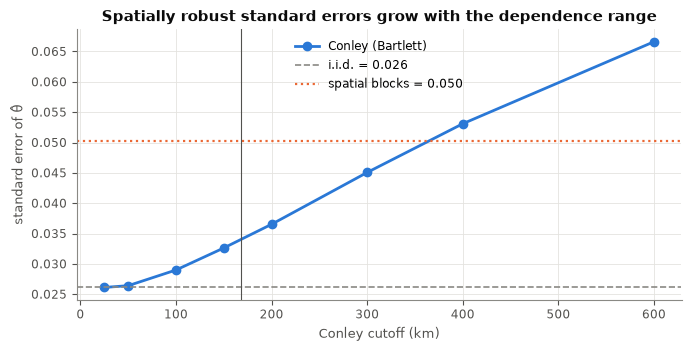

In [6]:
best = fits["RBF basis (155), auto blocks"]
psi = best.score_
d_star = sc.suggest_cutoff(best.residuals_["y"], xy)
print(f"suggested Conley cutoff from the outcome-residual correlogram: {d_star:.0f} km")

cutoffs = [25, 50, 100, 150, 200, 300, 400, 600]
se_c = [sc.standard_error(psi, xy, "conley", cutoff=c) for c in cutoffs]
se_iid = sc.standard_error(psi, method="iid")
se_blk = sc.standard_error(psi, xy, "block")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(cutoffs, se_c, "o-", color=ts.BLUE, label="Conley (Bartlett)")
ax.axhline(se_iid, color=ts.MUTED, ls="--", lw=1.2, label=f"i.i.d. = {se_iid:.3f}")
ax.axhline(se_blk, color=ts.ORANGE, ls=":", lw=1.6, label=f"spatial blocks = {se_blk:.3f}")
ax.axvline(d_star, color=ts.INK2, lw=0.8)
ax.set_xlabel("Conley cutoff (km)"); ax.set_ylabel("standard error of θ̂")
ax.set_title("Spatially robust standard errors grow with the dependence range")
ax.legend(); plt.tight_layout()

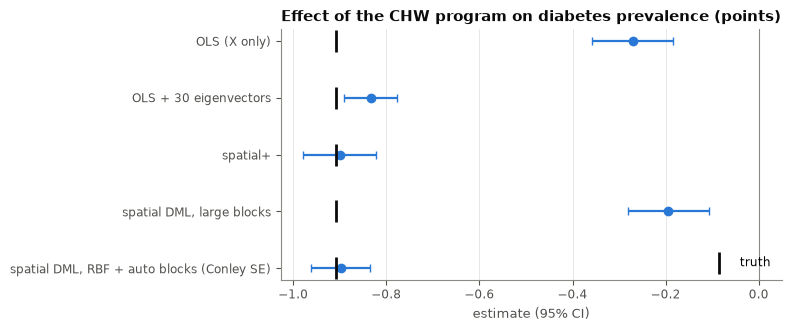

In [7]:
summary = pd.DataFrame({
    "estimate": [tbl.loc["OLS (X only)", "estimate"], tbl.loc["OLS + spatial smooth", "estimate"],
                 tbl.loc["spatial+", "estimate"], fits["coords + lag, 25 large blocks"].effect(),
                 best.effect()],
    "se": [tbl.loc["OLS (X only)", "se"], tbl.loc["OLS + spatial smooth", "se"], tbl.loc["spatial+", "se"],
           fits["coords + lag, 25 large blocks"].result_["ate"].se, sc.standard_error(psi, xy, "conley", cutoff=150)],
}, index=["OLS (X only)", "OLS + 30 eigenvectors", "spatial+", "spatial DML, large blocks",
          "spatial DML, RBF + auto blocks (Conley SE)"])
fig, ax = plt.subplots(figsize=(8, 3.4))
ts.forest(ax, summary.index, summary.estimate, summary.estimate - 1.96 * summary.se,
          summary.estimate + 1.96 * summary.se, truth=target,
          title="Effect of the CHW program on diabetes prevalence (points)", xlabel="estimate (95% CI)")
plt.tight_layout()

***
## Summary and Conclusions

1. A spatially smooth unmeasured confounder can flip the sign of a naive estimate and
   attenuate a covariate-adjusted one by ~70%.
2. "Adding space" works only if the spatial terms can actually represent the confounder.
   spatial+ achieves this by removing the smooth part of the *treatment*; DML achieves it
   with a rich basis.
3. Spatial cross-fitting needs blocks that are small relative to the confounder's scale; large
   blocks bring the bias back through extrapolation.
4. Report spatially robust standard errors and show their sensitivity to the cutoff.

No method can adjust for a confounder that is *not* spatially smooth and not measured; spatial
methods only help with the smooth part.


***
## Resources

### Papers

| Reference | Notes |
|-----------|-------|
| Hodges & Reich (2010) | A penalised spatial smooth can compete with treatment |
| Paciorek (2010) | Scale of spatial confounding and of the adjustment |
| Dupont, Wood & Augustin (2022) | spatial+: residualise treatment on a rich spatial basis first |
| Conley (1999) | Spatial HAC standard errors |
| Griffith; Dray, Legendre & Peres-Neto | Moran eigenvector maps |

### In this library

| Object | Role |
|--------|------|
| `diagnose_spatial_confounding` | Moran's I for $T$, $Y$, and both residuals |
| `compare_adjustments` | OLS, spatial smooth, and spatial+ side by side |
| `SpatialPlus` | Dupont, Wood & Augustin adjustment |
| `SpatialDML` | Partially linear DML with spatial-block cross-fitting |
| `suggest_cutoff` | Conley cutoff from the residual correlogram |
